# Exploring Hebrew Wikipedia

Before cleaning the data I want to see what's actually in it. Everything I find here turns into a rule in `normalize.py` (character level) or `prepare.py` (article level).

Data: Hebrew Wikipedia snapshot `20231101.he` from Hugging Face.



## 1. Load the data

In [ ]:
import pandas as pd

df = pd.read_parquet("../data/raw/hewiki.parquet")
print(df.shape)
df.head()

## 2. Read some random articles

In [3]:
sample = df.sample(3, random_state=42)

for _, row in sample.iterrows():
    print("=" * 80)
    print("TITLE:", row["title"])
    print("LENGTH:", len(row["text"]))
    print(row["text"][:2000])   # first 2000 characters

TITLE: 1501
LENGTH: 261


אירועים 
 אמריגו וספוצ'י מגיע לחוף ברזיל ומבין כי הגיע ליבשת חדשה, אמריקה.
 מיכלאנג'לו מתחיל לעבוד על פסלו, דוד.
 בשווייץ נוצרו הקנטונים בזל-שטאדט, בזל-לנדשאפט ושפהאוזן

נולדו 
 ג'רולאמו קארדאנו מתמטיקאי, פילוסוף ורופא איטלקי

נפטרו

לוח שנה

קישורים חיצוניים
TITLE: הרחבה רדיקלית
LENGTH: 857
במתמטיקה, ובעיקר בתורת גלואה, הרחבה רדיקלית היא הרחבת שדות הנוצרת על ידי סיפוח של ביטוי שורשי לשדה הבסיס. לדוגמה, השדה , המתקבל מסיפוח השורש הרביעי של 7 לשדה המספרים הרציונליים, הוא הרחבה רדיקלית (מממד 4) של , וגם הרחבה רדיקלית (מממד 2) של .

הרחבות רדיקליות הן מן הפשוטות ביותר בהרחבות של שדות, והמשפט המרכזי של תורת גלואה מאפיין את ההרחבות המתקבלות באמצעות שרשרת של הרחבות כאלה.

הרחבה רדיקלית אפשר לתאר גם באמצעות הבניה הסטנדרטית של חוגי מנה. אם  הוא שדה והפולינום  אי--פריק מעליו, אז  הוא הרחבה רדיקלית של , הנוצרת מסיפוח השורש ה--י של . כל הרחבה רדיקלית אפשר לתאר באופן כזה.

כאשר  כולל שורשי יחידה מסדר , כל הרחבה ציקלית מממד  מעל  היא הרחבה רדיקלית, ולהפך - כל הרחבה רדיקלית

**What I noticed:**
- Year articles like "1501" are mostly lists and empty headers (נפטרו, לוח שנה) with very little real text.
- In the math article, the formulas were removed during extraction, so sentences have holes like "השדה , המתקבל". There's nothing to recover, but it explains the double spaces I'll need to collapse.
- Every article ends with sections like קישורים חיצוניים followed by category names.

## 3. Count every character

I take a random sample of 10,000 articles and count how many times each character appears.

In [4]:
from collections import Counter
import unicodedata

sample_texts = df["text"].sample(10_000, random_state=0)

counter = Counter()
for text in sample_texts:
    counter.update(text)   # counts each character in the string

print("Unique characters:", len(counter))
print("\n--- 60 most common ---")
for ch, n in counter.most_common(60):
    print(repr(ch), hex(ord(ch)), unicodedata.name(ch, "UNKNOWN"), n)

Unique characters: 1772

--- 60 most common ---
' ' 0x20 SPACE 5208635
'י' 0x5d9 HEBREW LETTER YOD 2864018
'ו' 0x5d5 HEBREW LETTER VAV 2735109
'ה' 0x5d4 HEBREW LETTER HE 2027956
'ר' 0x5e8 HEBREW LETTER RESH 1527114
'ל' 0x5dc HEBREW LETTER LAMED 1521555
'ת' 0x5ea HEBREW LETTER TAV 1345932
'ב' 0x5d1 HEBREW LETTER BET 1336045
'מ' 0x5de HEBREW LETTER MEM 1213946
'א' 0x5d0 HEBREW LETTER ALEF 1131867
'ש' 0x5e9 HEBREW LETTER SHIN 1038300
'נ' 0x5e0 HEBREW LETTER NUN 893065
'ם' 0x5dd HEBREW LETTER FINAL MEM 663585
'ד' 0x5d3 HEBREW LETTER DALET 632624
'ע' 0x5e2 HEBREW LETTER AYIN 629486
'ק' 0x5e7 HEBREW LETTER QOF 604123
'פ' 0x5e4 HEBREW LETTER PE 552198
'ח' 0x5d7 HEBREW LETTER HET 541270
'ס' 0x5e1 HEBREW LETTER SAMEKH 532552
'כ' 0x5db HEBREW LETTER KAF 451883
'ג' 0x5d2 HEBREW LETTER GIMEL 400418
'ט' 0x5d8 HEBREW LETTER TET 398049
'\n' 0xa UNKNOWN 390196
',' 0x2c COMMA 366805
'צ' 0x5e6 HEBREW LETTER TSADI 316325
'.' 0x2e FULL STOP 309610
'ן' 0x5df HEBREW LETTER FINAL NUN 307641
'ז' 0x5d6 HEBREW 

## 4. Character coverage

In [5]:
total = sum(counter.values())
cumulative = 0
for i, (ch, n) in enumerate(counter.most_common(), start=1):
    cumulative += n
    if i in (50, 80, 100, 120, 150, 200, 300):
        print(f"Top {i} characters cover {cumulative / total:.4%} of all text")

Top 50 characters cover 97.8122% of all text
Top 80 characters cover 99.4960% of all text
Top 100 characters cover 99.7870% of all text
Top 120 characters cover 99.8784% of all text
Top 150 characters cover 99.9323% of all text
Top 200 characters cover 99.9632% of all text
Top 300 characters cover 99.9832% of all text


The top 100 characters cover 99.79% of the text, and the top 150 cover 99.93%. So I can keep a fixed set of allowed characters and lose almost nothing.

## 5. Rarest characters

In [6]:
print("--- 80 rarest ---")
for ch, n in counter.most_common()[-80:]:
    print(repr(ch), hex(ord(ch)), unicodedata.name(ch, "UNKNOWN"), n)

--- 80 rarest ---
'𑀮' 0x1102e BRAHMI LETTER LA 1
'𑀸' 0x11038 BRAHMI VOWEL SIGN AA 1
'ڑ' 0x691 ARABIC LETTER RREH 1
'ڈ' 0x688 ARABIC LETTER DDAL 1
'体' 0x4f53 CJK UNIFIED IDEOGRAPH-4F53 1
'操' 0x64cd CJK UNIFIED IDEOGRAPH-64CD 1
'競' 0x7af6 CJK UNIFIED IDEOGRAPH-7AF6 1
'技' 0x6280 CJK UNIFIED IDEOGRAPH-6280 1
'ង' 0x1784 KHMER LETTER NGO 1
'ំ' 0x17c6 KHMER SIGN NIKAHIT 1
'ព' 0x1796 KHMER LETTER PO 1
'瑞' 0x745e CJK UNIFIED IDEOGRAPH-745E 1
'章' 0x7ae0 CJK UNIFIED IDEOGRAPH-7AE0 1
'ǐ' 0x1d0 LATIN SMALL LETTER I WITH CARON 1
'ǎ' 0x1ce LATIN SMALL LETTER A WITH CARON 1
'ピ' 0x30d4 KATAKANA LETTER PI 1
'チ' 0x30c1 KATAKANA LETTER TI 1
'・' 0x30fb KATAKANA MIDDLE DOT 1
'ビ' 0x30d3 KATAKANA LETTER BI 1
'エ' 0x30a8 KATAKANA LETTER E 1
'整' 0x6574 CJK UNIFIED IDEOGRAPH-6574 1
'星' 0x661f CJK UNIFIED IDEOGRAPH-661F 1
'寺' 0x5bfa CJK UNIFIED IDEOGRAPH-5BFA 1
'ậ' 0x1ead LATIN SMALL LETTER A WITH CIRCUMFLEX AND DOT BELOW 1
'Խ' 0x53d ARMENIAN CAPITAL LETTER XEH 1
'Վ' 0x54e ARMENIAN CAPITAL LETTER VEW 1
'պ' 0x57a A

The rarest characters each appear only once: Chinese, Japanese, Korean, Armenian, Tifinagh, Syriac and others, usually a foreign name written in its original script. The model can't learn anything from a character it sees once, so these will be removed.

## 6. Characters by Unicode category

In [7]:
cat_counter = Counter()
for ch, n in counter.items():
    cat_counter[unicodedata.category(ch)] += n

for cat, n in cat_counter.most_common():
    print(cat, n)

Lo 24068543
Zs 5211662
Po 945223
Ll 748637
Nd 737943
Cc 390365
Lu 176370
Pd 153032
Ps 70452
Pe 70100
Mn 19478
Sm 3048
Pf 786
Pi 356
So 241
Pc 199
Sc 182
Cf 172
Lm 105
Mc 62
Sk 57
No 17


### What this shows

Every Unicode character has a category, so I grouped the characters in my sample by category to see what the text is actually made of. Most of it is Hebrew letters (Lo), spaces, punctuation, digits and some English, which is what I expected. Niqqud (Mn) is rare, so I'll strip it. There are also a few invisible formatting characters (Cf), like right-to-left marks, that I'll need to remove even though you can't see them in the text.

## 7. Trailing sections

Many articles end with sections like "See also" and "External links". I check how many articles contain them.

In [8]:
sections = ["ראו גם", "הערות שוליים", "קישורים חיצוניים", "לקריאה נוספת"]
for s in sections:
    count = df["text"].str.contains(s, regex=False).sum()
    print(f"{s}: {count:,} articles")

ראו גם: 55,742 articles
הערות שוליים: 210,043 articles
קישורים חיצוניים: 290,146 articles
לקריאה נוספת: 43,764 articles


These sections show up in most articles, and they aren't real text. They're mostly lists of links and references, or empty headers left over after the links were removed. If I keep them, the model will learn that every article ends with קישורים חיצוניים and הערות שוליים, and I'll waste training time on junk.

## 8. What the trailing sections look like

I print the last 600 characters of a few articles that contain קישורים חיצוניים, to see what comes before and after the header.

In [10]:
example = df[df["text"].str.contains("קישורים חיצוניים", regex=False)].sample(3, random_state=1)

for _, row in example.iterrows():
    print("=" * 80)
    print("TITLE:", row["title"])
    print(row["text"][-600:])   # last 600 characters

TITLE: נבחרת חבל הבסקים בכדורגל
נבחרת חבל הבסקים בכדורגל לגברים היא נבחרת הכדורגל של הקהילה האוטונומית של חבל הבסקים שבספרד.

מאחר שאינה מייצגת מדינה, נבחרת זו לא חברה באופ"א או בפיפ"א ולכן לא משתתפת בגביע העולם בכדורגל או באליפות אירופה בכדורגל.

בתחילת דרכה שיחקה הנבחרת רבות מול  הספרדית. בשנת 1937 יצאה הנבחרת מספרד לראשונה, לשם איסוף כספים עבור הבסקים בזמן מלחמת האזרחים בספרד. הנבחרת חדלה לפעול בזמן שנות פרנקו, ובשנת 1979 הוקמה מחדש.

קישורים חיצוניים

 

חבל הבסקים: ספורט
בסקים
חבל הבסקים
נווארה: ספורט
TITLE: תקווה חדשה
כלית, תקווה חדשה מאמינה בכלכלה חופשית, תמיכה בעסקים קטנים ובעצמאים, שוויון הזדמנויות ובצמצום הבירוקרטיה. בנוסף, המפלגה מעוניינת לשפר את מעמד המורים ומערכת החינוך וכמו כן להגדיל את תקצוב מערכת הבריאות ולהגדיל את סל השירותים לאזרח.

תקווה חדשה הכריזה כי היא דוגלת ברפורמות במערכות השלטון, לרבות הגבלת כהונה של ראש ממשלה וראשי רשויות מקומיות. בנוסף המפלגה מעוניינת להגדיל את סמכויות השלטון המקומי על חשבון סמכויות הממשל המרכזי.

ראשי המפלגה

חברי כנסת ותוצאות בחירות

קישור

What I noticed:
- The header always sits on its own line, so I can cut each article at the first line that is exactly one of these headers, without touching sentences that just mention them.
- Everything after the header is junk: link descriptions, empty lines and Wikipedia categories (like "גרמנים שנולדו ב-1891").
- Some section titles in the middle of articles (like "ראשי המפלגה") are left with no content because their tables were removed. I'll decide in `prepare.py` whether to drop short lines like these.

## 9. Article lengths

count    333874.000000
mean       3268.698916
std        4733.997430
min           1.000000
25%        1064.000000
50%        1953.000000
75%        3668.000000
max      170222.000000
Name: text, dtype: float64

Articles under 200 chars: 12226


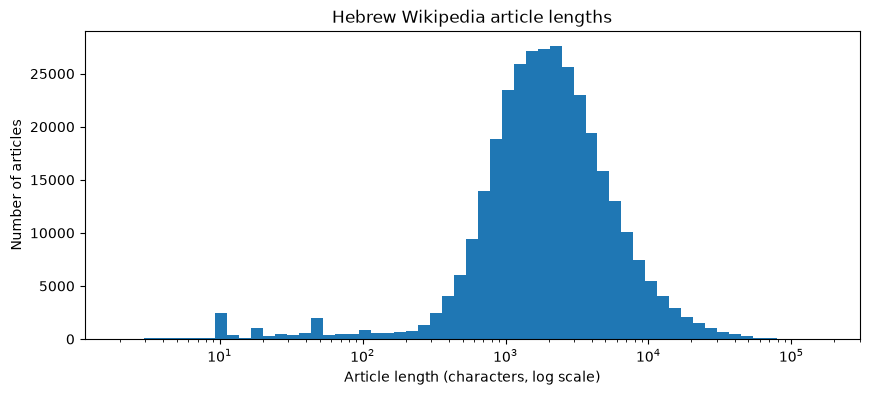

In [9]:
import matplotlib.pyplot as plt
import numpy as np

lengths = df["text"].str.len()
print(lengths.describe())
print("\nArticles under 200 chars:", (lengths < 200).sum())

bins = np.logspace(np.log10(lengths.min() + 1), np.log10(lengths.max()), 60)
plt.figure(figsize=(10, 4))
plt.hist(lengths, bins=bins)
plt.xscale("log")
plt.xlabel("Article length (characters, log scale)")
plt.ylabel("Number of articles")
plt.title("Hebrew Wikipedia article lengths")
plt.show()

The median article is about 2,000 characters long, and in total there are about 1.1 billion characters, which is plenty for a small model. 12,226 articles (about 3.7%) are shorter than 200 characters. These are mostly stubs and lists, so I'll drop them.

## Summary: what the cleaning needs to do

**`normalize.py` (characters)**
- Strip niqqud and cantillation marks
- Remove invisible format characters (like right-to-left marks)
- Unify quotes and dashes into one form each
- Collapse repeated spaces
- Keep only a fixed set of allowed characters (Hebrew, Latin letters, digits, common punctuation)

**`prepare.py` (articles)**
- Cut each article at the first trailing-section header
- Drop articles shorter than 200 characters
- Remove duplicates and split into train and validation sets